In [14]:
import scipy.io as sio
import numpy as np
from matplotlib import pyplot as plt
from scipy.signal import spectrogram

**LOADING DATA**

In [7]:
# Load the data
magnitude_data = sio.loadmat(r'Zakir_sitting\P01A\P0A1\Amplitude.mat')
phase_data = sio.loadmat(r'Zakir_sitting\P01A\P0A1\Phase.mat')

In [9]:
magnitude_data.keys(), phase_data.keys()

(dict_keys(['__header__', '__version__', '__globals__', 'Data_amplitude']),
 dict_keys(['__header__', '__version__', '__globals__', 'Data_phase']))

In [10]:
magnitude = magnitude_data["Data_amplitude"]  # replace 'variable_name' with the correct variable name
phase = phase_data["Data_phase"]

**Line Plots with 90 range bin (max) and Heatmap**

**Magnitude**

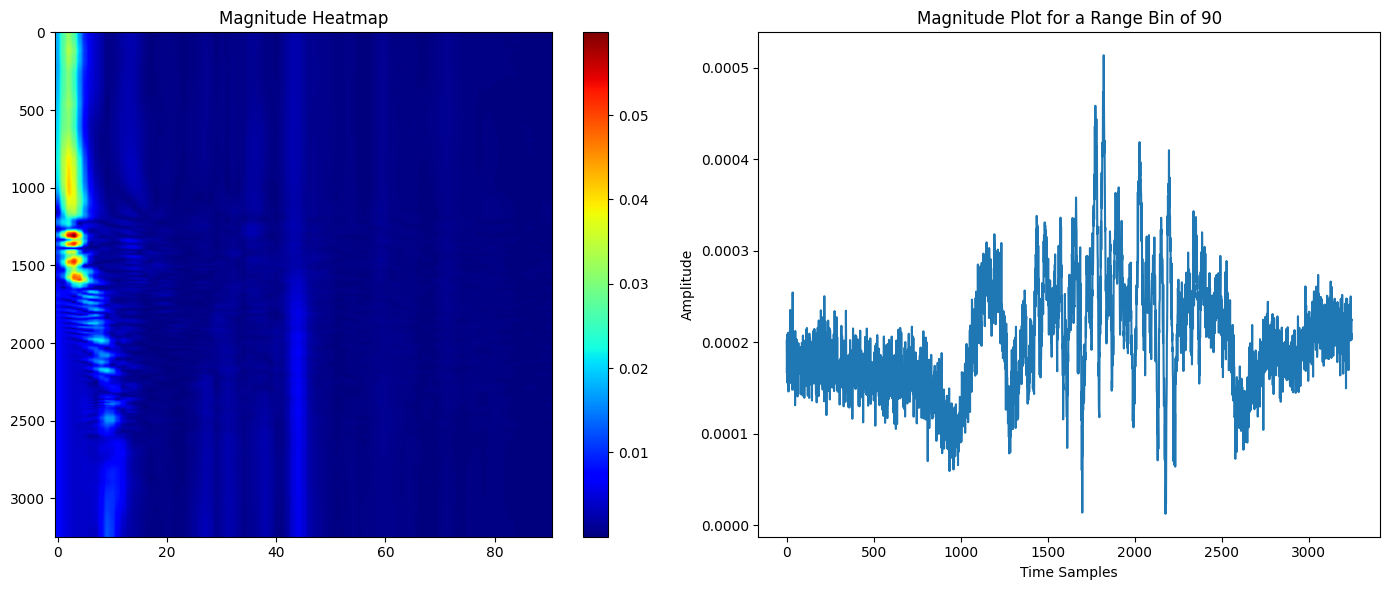

In [20]:
plt.figure(figsize=(14, 6))

# Heatmap of Magnitude
plt.subplot(1, 2, 1)
plt.imshow(magnitude, aspect='auto', cmap='jet')
plt.title('Magnitude Heatmap')
plt.colorbar()

# Line plot for a specific range bin 
plt.subplot(1, 2, 2)
range_bin_to_plot = 90
plt.plot(magnitude[:, range_bin_to_plot])
plt.title('Magnitude Plot for a Range Bin of 90')
plt.xlabel('Time Samples')
plt.ylabel('Amplitude')

plt.tight_layout()
plt.show()

**Phase**

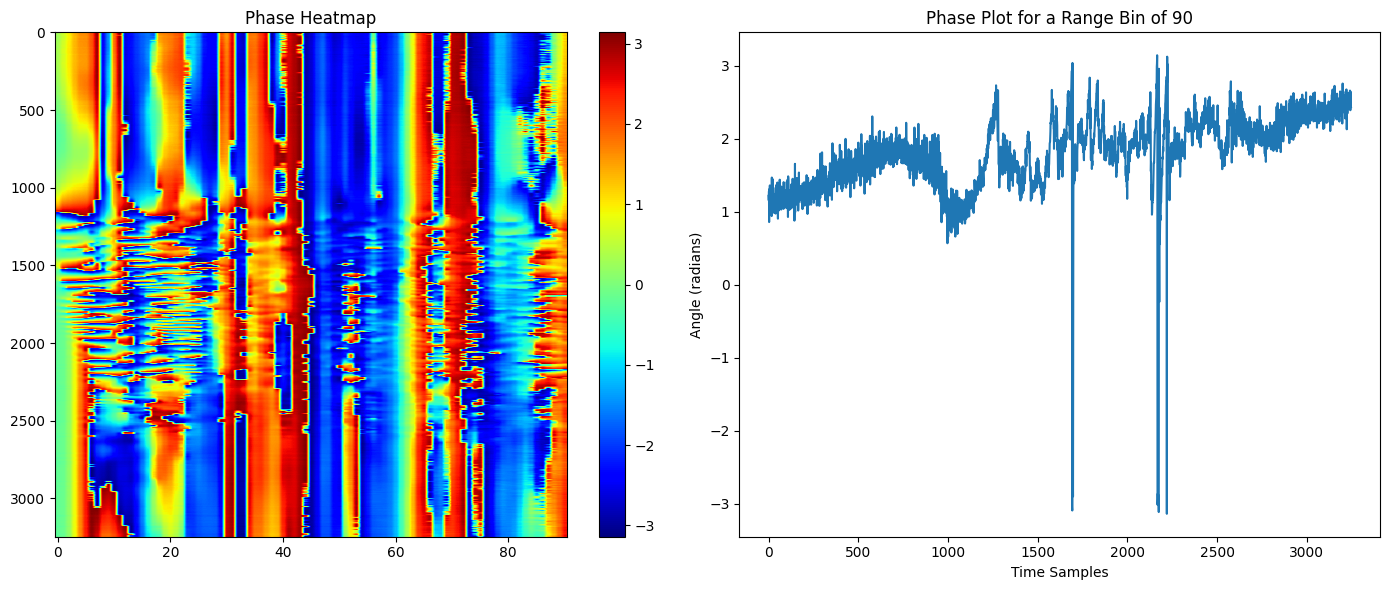

In [21]:
plt.figure(figsize=(14, 6))

# Heatmap of Phase
plt.subplot(1, 2, 1)
plt.imshow(phase, aspect='auto', cmap='jet')
plt.title('Phase Heatmap')
plt.colorbar()

# Line plot for a specific range bin 
plt.subplot(1, 2, 2)
range_bin_to_plot = 90
plt.plot(phase[:, range_bin_to_plot])
plt.title('Phase Plot for a Range Bin of 90')
plt.xlabel('Time Samples')
plt.ylabel('Angle (radians)')

plt.tight_layout()
plt.show()

**Spectrogram**

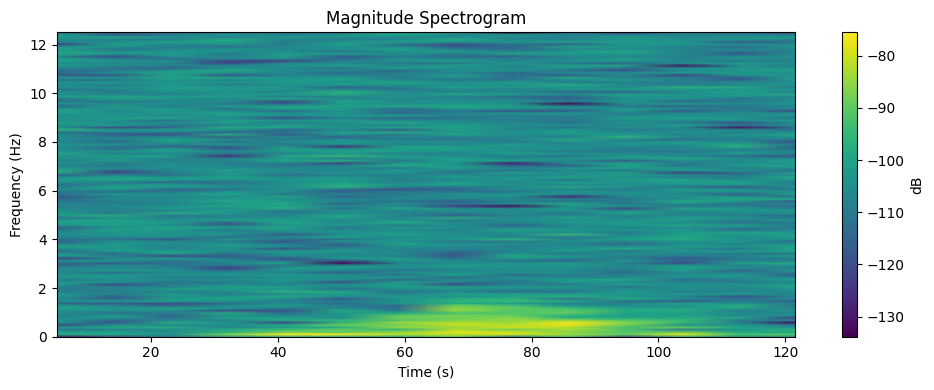

In [24]:
fs = 17

# Spectrogram for a specific range bin (modify the range bin index as needed)
range_bin_to_plot = 90
f, t, Sxx = spectrogram(magnitude[:, range_bin_to_plot], fs=fs)

plt.figure(figsize=(10, 4))
plt.pcolormesh(t, f, 10 * np.log10(Sxx), shading='gouraud')
plt.colorbar(label='dB')
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.title('Magnitude Spectrogram')
plt.tight_layout()
plt.show()

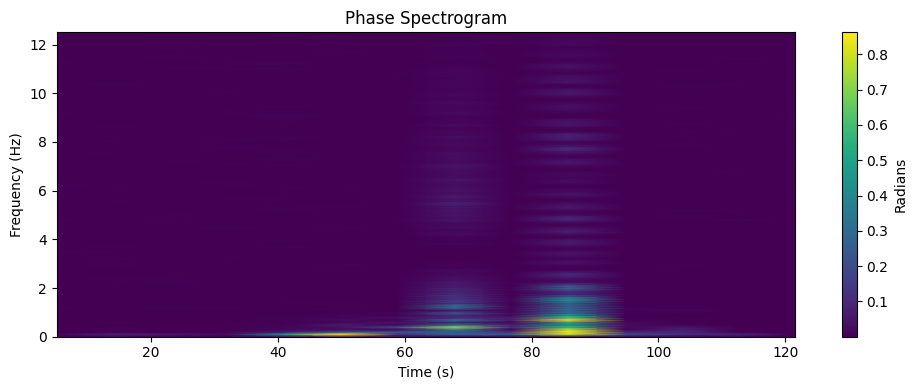

In [25]:
f, t, Sxx_phase = spectrogram(phase[:, range_bin_to_plot], fs=fs)

plt.figure(figsize=(10, 4))
plt.pcolormesh(t, f, Sxx_phase, shading='gouraud')  # Note: We don't convert phase to dB
plt.colorbar(label='Radians')
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.title('Phase Spectrogram')
plt.tight_layout()
plt.show()

**FFT**

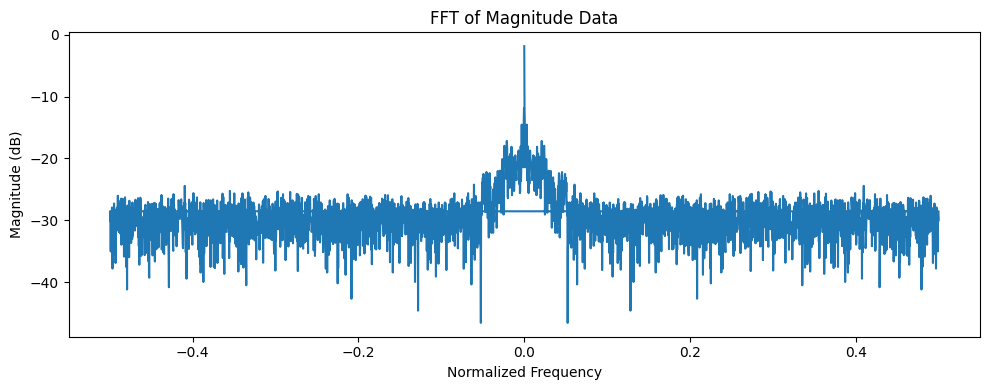

In [29]:
# Compute FFT for a specific range bin
range_bin_to_plot = 90
fft_values = np.fft.fft(magnitude[:, range_bin_to_plot])
frequencies = np.fft.fftfreq(len(fft_values))  # Normalized frequency values

plt.figure(figsize=(10, 4))
plt.plot(frequencies, 10 * np.log10(np.abs(fft_values)))
plt.title('FFT of Magnitude Data')
plt.xlabel('Normalized Frequency')
plt.ylabel('Magnitude (dB)')
plt.tight_layout()
plt.show()

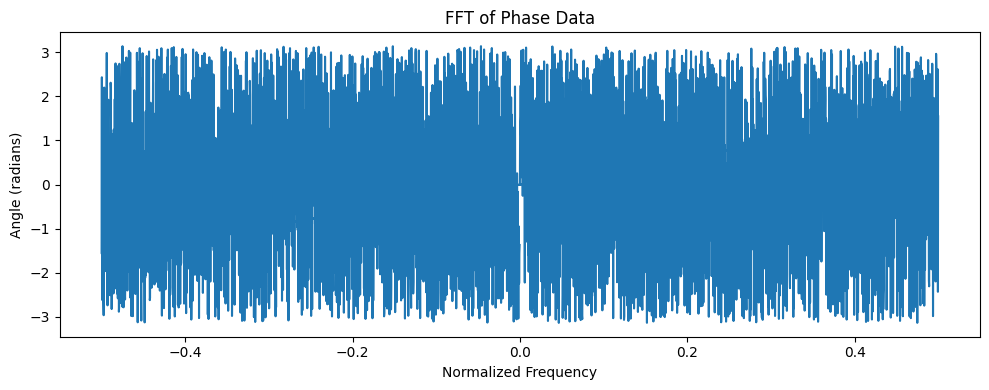

In [32]:
fft_values_phase = np.fft.fft(phase[:, range_bin_to_plot])

plt.figure(figsize=(10, 4))
plt.plot(frequencies, np.angle(fft_values_phase))
plt.title('FFT of Phase Data')
plt.xlabel('Normalized Frequency')
plt.ylabel('Angle (radians)')
plt.tight_layout()
plt.show()